[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Kaushikreddym/climdata/blob/main/docs/examples/indices/heatwave_germany.ipynb)

In [1]:
# Uncomment to install climdata (plus the plotting stack) in Colab or a fresh environment
# !pip install climdata
# !conda install -c conda-forge cartopy matplotlib -y

# Heat Waves over Germany — Download, Index, Map

This notebook runs a complete climdata workflow end to end:

1. **Download** DWD **HYRAS** 1 km gridded observations for Germany from the DWD Open Data server.
2. **Extract** `tasmin` and `tasmax` into a single `xarray.Dataset`.
3. **Compute heat wave indices** with xclim — and look at how much the *definition* changes the answer.
4. **Map the result** with Cartopy in **ETRS89-LAEA (EPSG:3035)**: the projection HYRAS is already on, and the standard equal-area projection for European gridded statistics.

**Why HYRAS?** It is the reference observational grid for Germany — 1 km spacing, daily, 1951 to present, built from the DWD station network, and freely downloadable with no account or API key.

| Variable | Description | Units |
|----------|-------------|-------|
| `tasmin` | Daily minimum air temperature | °C |
| `tasmax` | Daily maximum air temperature | °C |

> **Cost of a full run.** Each HYRAS variable-year is roughly 64 MB, so the ten years below are about **1.3 GB** of download and ~10 GB of memory while the indices are computed. Downloads are cached under `data_dir` and skipped on re-runs. Shorten `time_range` if you only want to see the mechanics.

## 1. Setup & imports

In [2]:
import warnings

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

from climdata import ClimData
from climdata.datasets.HYRAS import HYRASmirror

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

plt.rcParams.update({"figure.dpi": 110, "savefig.bbox": "tight"})

/beegfs/muduchuru/pkgs_fnl/climdata/climdata/utils/wrapper_workflow.py:36: ImportWarning: [climdata.impute] pycatch22 is not installed. Some imputation feature-extraction methods will be unavailable. Install it with: conda install -c conda-forge pycatch22
  from climdata.impute.impute_xarray import Imputer


## 2. Configure the request

Everything the workflow needs is expressed as Hydra overrides.

`region=germany` resolves to the bounding box defined in `conf/regions/regions.yaml` (47.0–55.5 °N, 5.9–15.0 °E), so there is no need to spell out coordinates. Both `tasmin` and `tasmax` are requested because the heat wave definitions compared below need day *and* night temperature.

In [3]:
base_overrides = [
    "dataset=hyras",                    # DWD HYRAS 1 km gridded observations
    "region=germany",                   # predefined bounding box
    "variables=[tasmin,tasmax]",        # day and night temperature
    "data_dir=./data",                  # download cache
    "time_range.start_date=2015-01-01",
    "time_range.end_date=2024-12-31",
]

extractor = ClimData(overrides=base_overrides + ["index=hot_spell_frequency"])
extractor.cfg.bounds[extractor.cfg.region]

{'lat_min': 47.0, 'lat_max': 55.5, 'lon_min': 5.9, 'lon_max': 15.0}

## 3. Download only

`HYRASmirror.fetch()` is the download step on its own: it works out the yearly file names covering `time_range`, skips whatever is already on disk, and pulls the rest from `opendata.dwd.de`. Nothing is opened or read into memory.

That separation is useful on a login node, or when staging data ahead of a batch job. Skip this cell and `extract()` below performs the same download itself.

In [4]:
hyras = HYRASmirror(extractor.cfg)
files = {var: hyras.fetch(var) for var in extractor.cfg.variables}

for var, paths in files.items():
    print(f"{var}: {len(paths)} yearly files in {extractor.cfg.data_dir}/HYRAS/{var.upper()}")

⬇️  Checking: https://opendata.dwd.de/climate_environment/CDC/grids_germany/daily/hyras_de/air_temperature_min/tasmin_hyras_1_2015_v6-1_de.nc
✔️  Exists locally: ./data/HYRAS/TASMIN/tasmin_hyras_1_2015_v6-1_de.nc
⬇️  Checking: https://opendata.dwd.de/climate_environment/CDC/grids_germany/daily/hyras_de/air_temperature_min/tasmin_hyras_1_2016_v6-1_de.nc
✔️  Exists locally: ./data/HYRAS/TASMIN/tasmin_hyras_1_2016_v6-1_de.nc
⬇️  Checking: https://opendata.dwd.de/climate_environment/CDC/grids_germany/daily/hyras_de/air_temperature_min/tasmin_hyras_1_2017_v6-1_de.nc
✔️  Exists locally: ./data/HYRAS/TASMIN/tasmin_hyras_1_2017_v6-1_de.nc
⬇️  Checking: https://opendata.dwd.de/climate_environment/CDC/grids_germany/daily/hyras_de/air_temperature_min/tasmin_hyras_1_2018_v6-1_de.nc
✔️  Exists locally: ./data/HYRAS/TASMIN/tasmin_hyras_1_2018_v6-1_de.nc
⬇️  Checking: https://opendata.dwd.de/climate_environment/CDC/grids_germany/daily/hyras_de/air_temperature_min/tasmin_hyras_1_2019_v6-1_de.nc
✔️  Ex

## 4. Extract into xarray

`extract()` downloads anything still missing, opens every yearly file, clips to the region, concatenates along time, and harmonises units to those declared in `cfg.varinfo`.

The result is Dask-backed and sits on the **native HYRAS grid**: projected `x` / `y` in metres, with two-dimensional `lat(y, x)` / `lon(y, x)` coordinates alongside them. Section 6 comes back to what that grid is.

In [5]:
ds = extractor.extract()
ds

⬇️  Checking: https://opendata.dwd.de/climate_environment/CDC/grids_germany/daily/hyras_de/air_temperature_min/tasmin_hyras_1_2015_v6-1_de.nc
✔️  Exists locally: ./data/HYRAS/TASMIN/tasmin_hyras_1_2015_v6-1_de.nc
⬇️  Checking: https://opendata.dwd.de/climate_environment/CDC/grids_germany/daily/hyras_de/air_temperature_min/tasmin_hyras_1_2016_v6-1_de.nc
✔️  Exists locally: ./data/HYRAS/TASMIN/tasmin_hyras_1_2016_v6-1_de.nc
⬇️  Checking: https://opendata.dwd.de/climate_environment/CDC/grids_germany/daily/hyras_de/air_temperature_min/tasmin_hyras_1_2017_v6-1_de.nc
✔️  Exists locally: ./data/HYRAS/TASMIN/tasmin_hyras_1_2017_v6-1_de.nc
⬇️  Checking: https://opendata.dwd.de/climate_environment/CDC/grids_germany/daily/hyras_de/air_temperature_min/tasmin_hyras_1_2018_v6-1_de.nc
✔️  Exists locally: ./data/HYRAS/TASMIN/tasmin_hyras_1_2018_v6-1_de.nc
⬇️  Checking: https://opendata.dwd.de/climate_environment/CDC/grids_germany/daily/hyras_de/air_temperature_min/tasmin_hyras_1_2019_v6-1_de.nc
✔️  Ex

<frozen importlib._bootstrap>:241: RuntimeWarning: numpy.ndarray size changed, may indicate binary incompatibility. Expected 16 from C header, got 96 from PyObject


⬇️  Checking: https://opendata.dwd.de/climate_environment/CDC/grids_germany/daily/hyras_de/air_temperature_max/tasmax_hyras_1_2015_v6-1_de.nc
✔️  Exists locally: ./data/HYRAS/TASMAX/tasmax_hyras_1_2015_v6-1_de.nc
⬇️  Checking: https://opendata.dwd.de/climate_environment/CDC/grids_germany/daily/hyras_de/air_temperature_max/tasmax_hyras_1_2016_v6-1_de.nc
✔️  Exists locally: ./data/HYRAS/TASMAX/tasmax_hyras_1_2016_v6-1_de.nc
⬇️  Checking: https://opendata.dwd.de/climate_environment/CDC/grids_germany/daily/hyras_de/air_temperature_max/tasmax_hyras_1_2017_v6-1_de.nc
✔️  Exists locally: ./data/HYRAS/TASMAX/tasmax_hyras_1_2017_v6-1_de.nc
⬇️  Checking: https://opendata.dwd.de/climate_environment/CDC/grids_germany/daily/hyras_de/air_temperature_max/tasmax_hyras_1_2018_v6-1_de.nc
✔️  Exists locally: ./data/HYRAS/TASMAX/tasmax_hyras_1_2018_v6-1_de.nc
⬇️  Checking: https://opendata.dwd.de/climate_environment/CDC/grids_germany/daily/hyras_de/air_temperature_max/tasmax_hyras_1_2019_v6-1_de.nc
✔️  Ex

<xarray.Dataset> Size: 32GB
Dimensions:  (time: 3653, y: 890, x: 619)
Coordinates:
  * time     (time) datetime64[ns] 29kB 2015-01-01 2015-01-02 ... 2024-12-31
  * y        (y) float64 7kB 2.674e+06 2.676e+06 ... 3.562e+06 3.564e+06
  * x        (x) float64 5kB 4.022e+06 4.022e+06 ... 4.638e+06 4.64e+06
    lon      (y, x) float64 4MB 6.055 6.068 6.081 6.094 ... 14.96 14.97 14.99
    lat      (y, x) float64 4MB 47.11 47.11 47.11 47.11 ... 55.08 55.08 55.08
Data variables:
    tasmin   (time, y, x) float64 16GB dask.array<chunksize=(30, 890, 619), meta=np.ndarray>
    tasmax   (time, y, x) float64 16GB dask.array<chunksize=(30, 890, 619), meta=np.ndarray>
Attributes: (12/22)
    source:                 surface observations
    institution:            Deutscher Wetterdienst (DWD)
    Conventions:            CF-1.11
    title:                  gridded_temperature_dataset_(HYRAS TASMIN)
    realization:            v6-1
    project_id:             HYRAS
    ...                     ...
    variable_id:            tasmin
    ConventionsURL:         http://cfconventions.org/Data/cf-conventions/cf-c...
    license:                The HYRAS data, produced by DWD, is licensed unde...
    filename:               tasmin_hyras_1_2015_v6-1_de.nc
    comment:                Please be aware that the parameters are stored as...
    unique_dataset_id:      DWD_HYRAS_DE_tasmin_v6-1_2015_286b4f4d-ac22-440e-...

### Rechunk before computing indices

Heat wave indices are *run-length* statistics — they look for consecutive days, so every task needs an unbroken stretch of time. The files arrive chunked along `time`, which is exactly the wrong way round: rechunk to complete time series over small spatial tiles instead.

Casting to `float32` halves the memory. HYRAS ships as `float64`, far more precision than a gridded temperature analysis actually carries.

In [6]:
ds = ds.astype("float32").chunk({"time": -1, "y": 150, "x": 150})

# HYRAS is masked to German territory. Keep that mask: the indices return
# integer counts, which would otherwise fill the sea and the neighbours with
# a perfectly plausible-looking zero.
land = ds["tasmax"].isel(time=0).notnull().compute()

print("time chunks:", ds.chunks["time"], "| land cells:", int(land.sum()))

time chunks: (3653,) | land cells: 359156


## 5. Choosing a heat wave definition

There is no single definition of a heat wave, and over Germany the choice matters more than it might seem. climdata exposes the xclim families through `conf/mappings/indices.yaml`; three are worth comparing.

| Index | Criterion | Notes |
|-------|-----------|-------|
| `hot_spell_frequency` | `tasmax` > 30 °C on ≥ 3 consecutive days | Day-time only. A run of DWD *heiße Tage* — the working definition behind most German heat warnings. xclim's defaults already match it. |
| `hot_spell_total_length` | same, counted in days | Separates one long event from several short ones. |
| `heat_wave_frequency` | `tasmin` > thresh **and** `tasmax` > 30 °C on ≥ 3 consecutive days | Day *and* night. Stricter, and captures the lack of night-time recovery that makes heat waves dangerous. |

`heat_wave_frequency` defaults to `thresh_tasmin="22 degC"`, from the Meehl & Tebaldi definition calibrated on the United States. German night minima rarely hold above 22 °C for three nights running, so those defaults return almost nothing here — we compute them anyway, below, rather than take that on trust, and compare against a night threshold of 18 °C.

Any argument of any configured index can be overridden from the command line or the `overrides` list; `+` tells Hydra the key is new rather than a replacement.

In [7]:
def compute_index(name, extra=()):
    """Run one configured index over `ds` and mask it to the HYRAS domain."""
    ex = ClimData(overrides=base_overrides + [f"index={name}", *extra])
    return ex.calc_index(ds)[name].where(land)


# Day-time spells: tasmax > 30 degC for at least 3 consecutive days (xclim defaults).
hsf = compute_index("hot_spell_frequency")
hsd = compute_index("hot_spell_total_length")

# Day + night, with xclim's default 22 degC night threshold and with 18 degC.
hwf_22 = compute_index("heat_wave_frequency")
hwf_18 = compute_index("heat_wave_frequency",
                       ["+extinfo.indices.heat_wave_frequency.args.thresh_tasmin='18 degC'"])

hsf = hsf.assign_attrs(long_name="Hot spell frequency", units="events year-1")
hsd = hsd.assign_attrs(long_name="Hot spell days", units="days year-1")
hsf

<xarray.DataArray 'hot_spell_frequency' (time: 10, y: 890, x: 619)> Size: 44MB
array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
...
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]]], shape=(10, 890, 619))
Coordinates:
  * time     (time) datetime64[ns] 80B 2015-01-01 2016-01-01 ... 2024-01-01
  * y        (y) float64 7kB 2.674e+06 2.676e+06 ... 3.562e+06 3.564e+06
  * x        (x) float64 5kB 4.022e+06 4.022e+06 ... 4.638e+06 4.64e+06
    lon      (y, x) float64 4MB 6.055 6.068 6.081 6.094 ... 14.96 14.97 14.99
    lat      (y, x) float64 4MB 47.11 47.11 47.11 47.11 ... 55.08 55.08 55.08
Attributes:
    units:      events year-1
    long_name:  Hot spell frequency

(The `>= 30 years` warning is climdata pointing out that index *climatologies* normally want a 30-year baseline. Ten years is fine for looking at individual years, which is what we do here.)

### How much does the definition change the answer?

In [8]:
years = pd.to_datetime(hsf["time"].values).year

comparison = pd.DataFrame({
    "year": years,
    "hot spells (>30 °C, 3 d)": hsf.mean(("y", "x")).values,
    "hot spell days": hsd.mean(("y", "x")).values,
    "heat waves (night >18 °C)": hwf_18.mean(("y", "x")).values,
    "heat waves (night >22 °C)": hwf_22.mean(("y", "x")).values,
}).set_index("year").round(3)

comparison.loc["mean"] = comparison.mean().round(3)
comparison

,"hot spells (>30 °C, 3 d)",hot spell days,heat waves (night >18 °C),heat waves (night >22 °C)
year,,,,
2015,1.927,8.587,0.318,0.0
2016,1.169,4.298,0.010,0.0
2017,0.515,1.846,0.006,0.0
2018,2.165,10.942,0.354,0.0
2019,2.053,8.466,0.176,0.0
2020,1.261,6.129,0.209,0.0
2021,0.777,2.760,0.091,0.0
2022,1.693,6.138,0.001,0.0
2023,0.876,3.653,0.063,0.0


The day-time definition gives a usable signal across the whole country. Requiring warm nights as well thins it out by roughly an order of magnitude, and xclim's 22 °C default all but empties the map — a reminder that a threshold calibrated for one continent is not portable to another.

The rest of the notebook maps `hot_spell_frequency`, and returns to the comparison in section 10.

## 6. The right projection for Germany

A plain lat/lon (`PlateCarree`) map of Germany is visibly stretched: at 51 °N a degree of longitude covers only about 63 % of the ground a degree of latitude does, so the country comes out too wide and areas are wrong.

HYRAS has already solved this. Its grid is **ETRS89 / LAEA Europe (EPSG:3035)** — a Lambert Azimuthal Equal-Area projection centred on 10 °E, 52 °N. It is the projection INSPIRE and Eurostat mandate for pan-European gridded statistics, and being equal-area it means *one grid cell covers one square kilometre anywhere in the domain*. That is what makes the plain unweighted spatial mean used above a legitimate national average.

So rather than hardcoding a projection, read it off the CF `grid_mapping` variable HYRAS ships and hand those parameters to Cartopy.

In [9]:
def cartopy_crs_from_cf(ds, grid_mapping="crs"):
    """Build a Cartopy projection from a CF-convention grid_mapping variable."""
    a = ds[grid_mapping].attrs
    name = a["grid_mapping_name"]
    globe = ccrs.Globe(
        semimajor_axis=a.get("semi_major_axis"),
        semiminor_axis=a.get("semi_minor_axis"),
    )
    if name == "lambert_azimuthal_equal_area":
        return ccrs.LambertAzimuthalEqualArea(
            central_longitude=a.get("longitude_of_central_meridian",
                                    a.get("longitude_of_projection_origin", 0.0)),
            central_latitude=a["latitude_of_projection_origin"],
            false_easting=a.get("false_easting", 0.0),
            false_northing=a.get("false_northing", 0.0),
            globe=globe,
        )
    raise NotImplementedError(f"No Cartopy mapping for grid_mapping_name={name!r}")


# extract() keeps only the requested variables, so read the grid_mapping back
# from one of the raw files still sitting in the download cache.
raw = xr.open_dataset(files["tasmax"][0], decode_timedelta=False)
LAEA = cartopy_crs_from_cf(raw)

print(raw["crs"].attrs["epsg_code"], "->", LAEA)

EPSG:3035 -> +proj=laea +ellps=WGS84 +a=6378137.0 +b=6356752.31414036 +lon_0=10.0 +lat_0=52.0 +x_0=4321000.0 +y_0=3210000.0 +no_defs +type=crs


Two shortcuts are worth knowing:

* `ccrs.Projection("EPSG:3035")` builds the same projection in one line through pyproj, if you already know the EPSG code.
* Because `x` / `y` *are* LAEA metres, drawing them with `transform=LAEA` puts every cell exactly where it belongs with no reprojection of the data at all. Drawing `lon` / `lat` with `transform=ccrs.PlateCarree()` is equally correct, just slower — Cartopy then has to transform half a million cell corners.

If you need the data itself on another grid — to match a different dataset, say — that is `extractor.reproject()` rather than a plotting concern.

## 7. Quick look with `climdata.plot_map`

For a fast sanity check, climdata ships `plot_map()`, a thin Cartopy wrapper around `xarray.plot`. Hand it the projection and it takes care of coastlines, borders, gridlines and the colorbar.

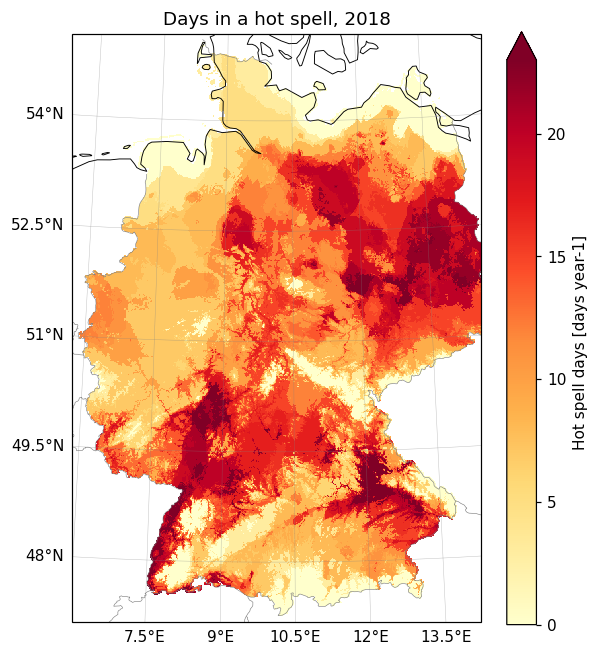

In [10]:
extractor.plot(
    ds=hsd.to_dataset(name="hot_spell_days"),
    variable="hot_spell_days",
    time="2018-01-01",
    projection=LAEA,
    cmap="YlOrRd",
    figsize=(6, 7),
    title="Days in a hot spell, 2018",
)
plt.show()

## 8. A presentable map: the 2015–2024 average

For the real figure, drive Matplotlib and Cartopy directly. The points that matter:

* `subplot_kw={"projection": LAEA}` puts the axes in the data's own CRS.
* `set_extent(..., crs=ccrs.PlateCarree())` still takes plain lon/lat, which is the convenient way to frame a country.
* `pcolormesh` over `x` / `y` with `transform=LAEA` is the exact, no-resampling path.
* Ocean and neighbouring land go *underneath* the field, so the masked HYRAS domain reads as the subject of the map rather than a hole in it.

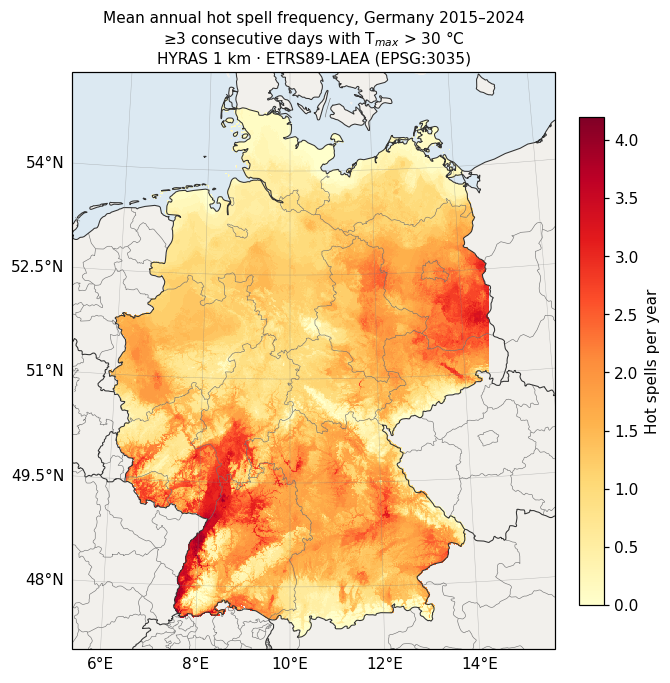

In [11]:
hsf_mean = hsf.mean("time")

fig, ax = plt.subplots(figsize=(7, 8), subplot_kw={"projection": LAEA})
ax.set_extent([5.4, 15.6, 47.0, 55.3], crs=ccrs.PlateCarree())

ax.add_feature(cfeature.OCEAN.with_scale("10m"), facecolor="#dce9f2", zorder=0)
ax.add_feature(cfeature.LAND.with_scale("10m"), facecolor="#f2f0ec", zorder=0)

mesh = ax.pcolormesh(
    hsf_mean["x"], hsf_mean["y"], hsf_mean,
    transform=LAEA, cmap="YlOrRd", vmin=0, vmax=float(hsf_mean.max()),
    shading="auto", zorder=1,
)

ax.add_feature(cfeature.NaturalEarthFeature(
    "cultural", "admin_1_states_provinces_lines", "10m", facecolor="none"),
    edgecolor="0.45", linewidth=0.4, zorder=2)
ax.add_feature(cfeature.BORDERS.with_scale("10m"), edgecolor="0.2", linewidth=0.7, zorder=2)
ax.coastlines("10m", linewidth=0.7, color="0.2", zorder=2)

gl = ax.gridlines(draw_labels=True, linewidth=0.3, color="gray", alpha=0.5, zorder=3)
gl.top_labels = gl.right_labels = False

cbar = fig.colorbar(mesh, ax=ax, orientation="vertical", shrink=0.72, pad=0.04)
cbar.set_label("Hot spells per year")

ax.set_title(
    "Mean annual hot spell frequency, Germany 2015–2024\n"
    "≥3 consecutive days with T$_{max}$ > 30 °C\n"
    "HYRAS 1 km · ETRS89-LAEA (EPSG:3035)",
    fontsize=10,
)
plt.show()

The pattern is the expected one. Hot spells concentrate in the **Upper Rhine Graben** — the warmest part of the country and clearly the maximum here — together with the **Rhine-Main** area and the sheltered lowland basins of eastern Germany around Berlin, Saxony-Anhalt and Saxony. They fall away towards the **North Sea and Baltic coasts**, where the sea damps the summer maximum, and towards the **uplands and the Alpine foreland**, where elevation does. At 1 km the Black Forest, Harz, Thuringian Forest and Erzgebirge all show up as cool ridges against their surroundings.

## 9. Year by year

The decadal mean hides how uneven these years were. A shared colour scale makes the contrast legible.

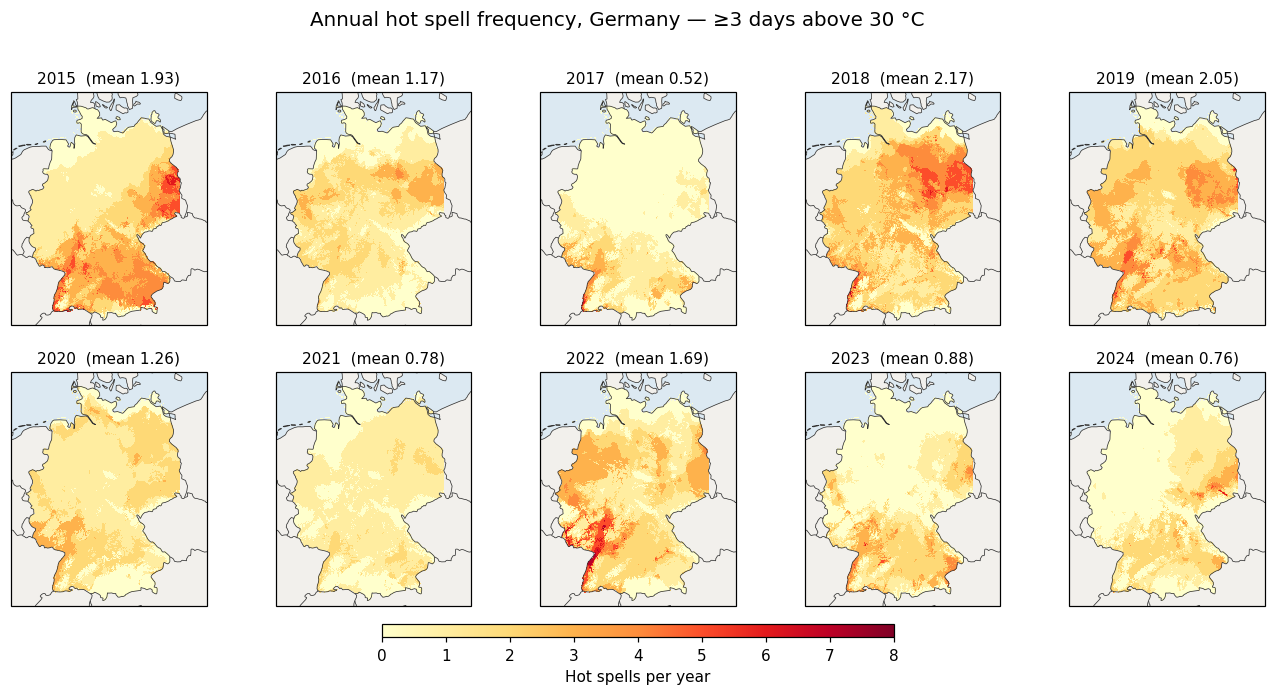

In [12]:
n = hsf.sizes["time"]
ncols = 5
nrows = int(np.ceil(n / ncols))
vmax = float(hsf.max())

fig, axes = plt.subplots(nrows, ncols, figsize=(3.0 * ncols, 3.7 * nrows),
                         subplot_kw={"projection": LAEA})

for i, ax in enumerate(axes.ravel()):
    if i >= n:
        ax.axis("off")
        continue
    field = hsf.isel(time=i)
    ax.set_extent([5.4, 15.6, 47.0, 55.3], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.OCEAN.with_scale("50m"), facecolor="#dce9f2", zorder=0)
    ax.add_feature(cfeature.LAND.with_scale("50m"), facecolor="#f2f0ec", zorder=0)
    mesh = ax.pcolormesh(field["x"], field["y"], field, transform=LAEA,
                         cmap="YlOrRd", vmin=0, vmax=vmax, shading="auto", zorder=1)
    ax.add_feature(cfeature.BORDERS.with_scale("50m"), edgecolor="0.2", linewidth=0.5, zorder=2)
    ax.coastlines("50m", linewidth=0.5, color="0.2", zorder=2)
    ax.set_title(f"{years[i]}  (mean {float(field.mean()):.2f})", fontsize=10)

cbar = fig.colorbar(mesh, ax=axes, orientation="horizontal",
                    shrink=0.4, pad=0.03, aspect=40)
cbar.set_label("Hot spells per year")
fig.suptitle("Annual hot spell frequency, Germany — ≥3 days above 30 °C",
             y=0.98, fontsize=13)
plt.show()

## 10. Three definitions, one decade

Back to section 5, now as maps. The same ten years, the same grid, three criteria — each with its own colour scale, because the magnitudes differ by an order of magnitude.

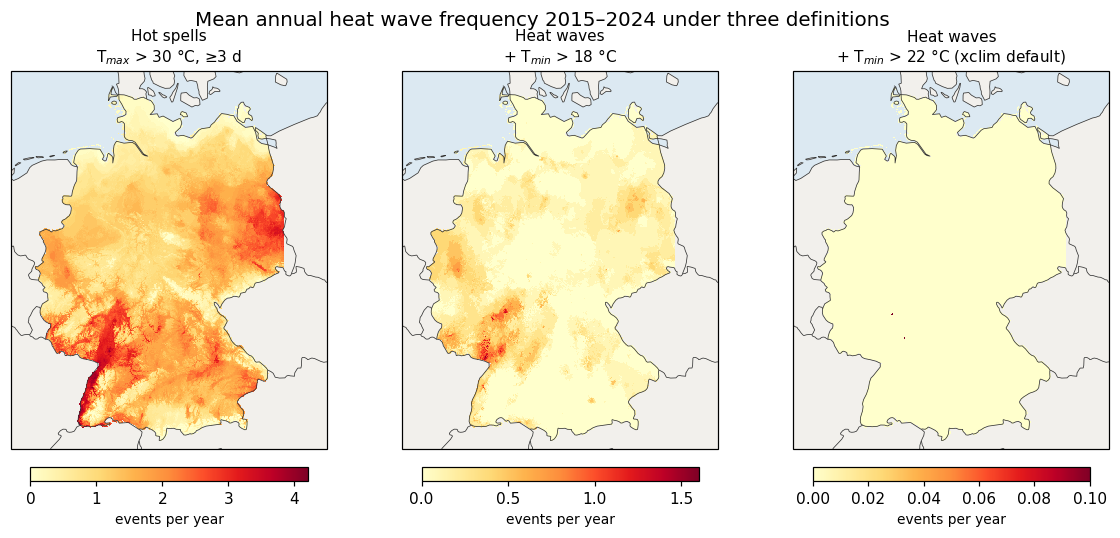

In [13]:
panels = [
    (hsf.mean("time"), "Hot spells\nT$_{max}$ > 30 °C, ≥3 d", "events per year"),
    (hwf_18.mean("time"), "Heat waves\n+ T$_{min}$ > 18 °C", "events per year"),
    (hwf_22.mean("time"), "Heat waves\n+ T$_{min}$ > 22 °C (xclim default)", "events per year"),
]

fig, axes = plt.subplots(1, 3, figsize=(13, 5.5), subplot_kw={"projection": LAEA})

for ax, (field, title, label) in zip(axes, panels):
    ax.set_extent([5.4, 15.6, 47.0, 55.3], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.OCEAN.with_scale("50m"), facecolor="#dce9f2", zorder=0)
    ax.add_feature(cfeature.LAND.with_scale("50m"), facecolor="#f2f0ec", zorder=0)
    vmax = float(field.max())
    mesh = ax.pcolormesh(field["x"], field["y"], field, transform=LAEA, cmap="YlOrRd",
                         vmin=0, vmax=vmax if vmax > 0 else 1, shading="auto", zorder=1)
    ax.add_feature(cfeature.BORDERS.with_scale("50m"), edgecolor="0.2", linewidth=0.5, zorder=2)
    ax.coastlines("50m", linewidth=0.5, color="0.2", zorder=2)
    ax.set_title(title, fontsize=10)
    cb = fig.colorbar(mesh, ax=ax, orientation="horizontal", shrink=0.85, pad=0.04)
    cb.set_label(label, fontsize=9)

fig.suptitle("Mean annual heat wave frequency 2015–2024 under three definitions", fontsize=13)
plt.show()

Note that the three maps do not merely rescale one another. The night-time criterion shifts weight towards the Rhine valley and the large cities, where nights stay warmest, and erases the eastern lowland maximum almost entirely — the definition changes *where* the hazard appears to be, not just how much of it there is.

## 11. The national time series

Frequency and duration tell different stories, so plot them together. Because the grid is equal-area, `mean(("y", "x"))` over the masked domain is a genuine area-weighted German average.

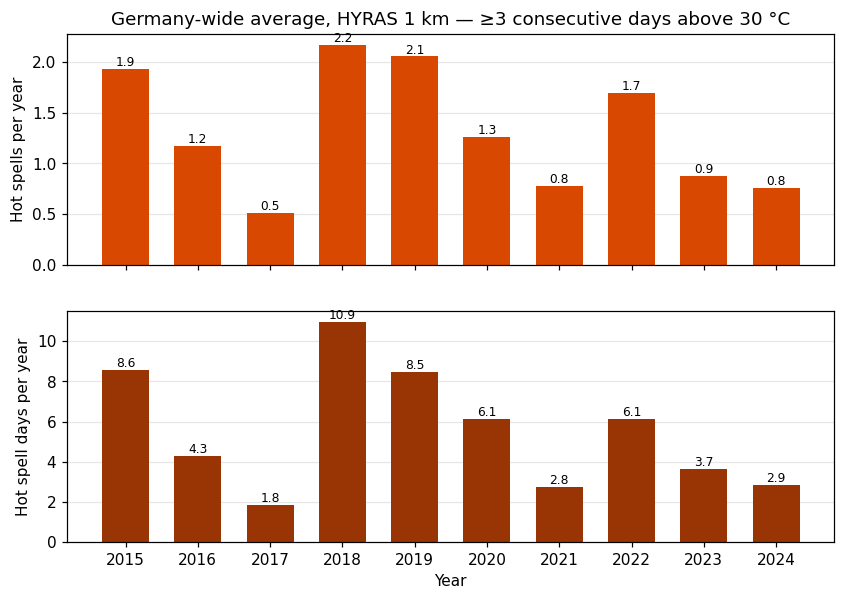

In [14]:
mean_events = hsf.mean(("y", "x")).values
mean_days = hsd.mean(("y", "x")).values

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True)

ax1.bar(years, mean_events, color="#d94801", width=0.65)
ax1.set_ylabel("Hot spells per year")
ax1.set_title("Germany-wide average, HYRAS 1 km — ≥3 consecutive days above 30 °C")

ax2.bar(years, mean_days, color="#993404", width=0.65)
ax2.set_ylabel("Hot spell days per year")
ax2.set_xlabel("Year")

for ax, vals in ((ax1, mean_events), (ax2, mean_days)):
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
    for xx, vv in zip(years, vals):
        ax.text(xx, vv, f"{vv:.1f}", ha="center", va="bottom", fontsize=8)

ax2.set_xticks(years)
plt.show()

## 12. Save the results

The index fields are one map per year, so a single NetCDF holds all three cleanly. The national means from section 5 go out as a small CSV.

Resist the temptation to dump the grid itself to CSV: `to_dataframe()` on a 1 km field over ten years is 5.5 million rows and a quarter of a gigabyte of text. `extractor.to_dataframe()` / `to_csv()` are there for point and station extractions, where long form is the natural shape. For a grid, stay in NetCDF or Zarr.

In [15]:
out = xr.merge([
    hsf.rename("hot_spell_frequency"),
    hsd.rename("hot_spell_total_length"),
    hwf_18.rename("heat_wave_frequency_tn18"),
])
out.attrs.update(
    title="Heat wave indices for Germany from DWD HYRAS",
    source="HYRAS v6-1, Deutscher Wetterdienst (DWD), https://opendata.dwd.de",
    definitions=("hot_spell_*: tasmax > 30 degC for >= 3 consecutive days; "
                 "heat_wave_frequency_tn18: additionally tasmin > 18 degC"),
    grid="ETRS89-LAEA (EPSG:3035), 1 km",
    created_with="climdata",
)

out.to_netcdf("heatwave_germany_2015_2024.nc")
comparison.to_csv("heatwave_germany_national_means.csv")

print(out)

<xarray.Dataset> Size: 119MB
Dimensions:                   (y: 890, x: 619, time: 10)
Coordinates:
  * y                         (y) float64 7kB 2.674e+06 2.676e+06 ... 3.564e+06
  * x                         (x) float64 5kB 4.022e+06 4.022e+06 ... 4.64e+06
  * time                      (time) datetime64[ns] 80B 2015-01-01 ... 2024-0...
    lon                       (y, x) float64 4MB 6.055 6.068 ... 14.97 14.99
    lat                       (y, x) float64 4MB 47.11 47.11 ... 55.08 55.08
Data variables:
    hot_spell_frequency       (time, y, x) float64 44MB nan nan nan ... nan nan
    hot_spell_total_length    (time, y, x) float32 22MB nan nan nan ... nan nan
    heat_wave_frequency_tn18  (time, y, x) float64 44MB nan nan nan ... nan nan
Attributes:
    units:         events year-1
    long_name:     Hot spell frequency
    title:         Heat wave indices for Germany from DWD HYRAS
    source:        HYRAS v6-1, Deutscher Wetterdienst (DWD), https://opendata...
    definitions:   hot

## Where to go next

* **Other heat indices.** `hot_spell_max_length`, `hot_spell_max_magnitude`, `heat_wave_max_length`, `tropical_nights`. See what is available for the variables you have with `extractor.get_indices(["tasmin", "tasmax"])`.
* **Percentile-based definitions.** A fixed 30 °C threshold is easy to explain but says nothing about local acclimatisation; a relative threshold such as the 90th percentile of the 1971–2000 daily maximum adapts to the local climate and is what most detection-and-attribution work uses. Those indices need a long baseline, so extend `time_range` first.
* **Projections instead of observations.** Swap `dataset=hyras` for `dataset=nexgddp` or `dataset=cmip_w5e5` with an `experiment_id` such as `ssp585`, and the same index code gives the future signal. `docs/examples/advanced/cmip_obs_comparison.ipynb` sets up that comparison.
* **A different grid.** `extractor.reproject(target_projection="EPSG:25832", target_resolution="5 km")` moves the result onto whatever CRS and resolution another dataset needs.